# 21 Tagesmonitor mit CUSUM

- Ansatz aus dem Normalverhaltensmodell übernommen: Abkühlung in kWh/m³ und Tagesvolumen je Station über der Tagesmitteltemperatur lernen; ein CUSUM meldet, wenn eine Station über mehrere Heiztage von ihrer eigenen Kennlinie wegläuft.
- CUSUM: Tagesabweichungen in Streuungseinheiten werden aufsummiert, je Tag wird k = 0,5 abgezogen. Alarm, sobald das Konto die Schwelle h = 5 überschreitet.
- Dazu die Abkühlung bei 5 °C als zweite Sicht auf das Netz und eine wetterbereinigte Differenz-in-Differenzen (DiD) für die Wirkung einer Begehung.
- Stundenreihen aus Notebook 00; Logik in `src/tagesmonitor.py`, Einbindung in `src/stationsblatt.py`, Doku in `docs/kennlinien-monitor.md`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import stationsblatt as bl
from src import tagesmonitor as tm

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

BEISPIEL = 68956351

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"])
r = erg["tagesmonitor"]
termine = erg["termine"]
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")

100 Stundenreihen aus NB 00, gerechnet in 2034 s


## Tageswerte und Ausschlüsse

- Energie und Volumen eines Tages aus den Zählerständen um Mitternacht. Ausschlussgründe wie in Notebook 06; wenige Stundenwerte allein schließen nicht aus, weil die frühen Jahre teils nur Tageswerte haben.
- Heiztag: Tagesmittel unter 15 °C.

In [2]:
tage = r["tage"]
print(f"{len(tage)} Stationstage, davon {int(tage['nutzbar'].sum())} nutzbar, "
      f"{len(r['modelltage'])} nutzbare Heiztage")
r["ausschluss"]

94607 Stationstage, davon 81073 nutzbar, 58232 nutzbare Heiztage


,grund,tage,stationen,ignoriert
0,kein_zaehlerstand,256,100,False
1,ruecksprung,3,1,False
2,zaehler_steht,38,4,False
3,nach_stillstand,38,4,False
4,wenig_energie,13201,60,False
5,unplausibel,19,9,False
6,wenig_stunden,22206,96,True
7,ohne_wetter,48,48,False


## Referenzjahr je Station

- Gelernt wird im ersten Jahr ab dem ersten nutzbaren Heiztag, bei früherer Begehung nur bis 14 Tage davor.
- Mindestens 60 Heiztage und 8 K Temperaturspanne, sonst keine Überwachung.

In [3]:
ref = r["referenz"]
display(ref["status"].value_counts().rename("Stationen").to_frame())
display(ref.groupby("ende_grund")[["ref_tage", "ref_spanne_k",
                                   "ueberwachte_tage"]].median().round(1))

,Stationen
status,
ok,92
keine Tage nach der Referenz,5
zu wenige Referenztage,1


,ref_tage,ref_spanne_k,ueberwachte_tage
ende_grund,,,
ein Jahr,229.0,20.0,488.5
vor Begehung,209.5,21.0,240.0


## Hilft die Temperatur überhaupt?

- Erste 120 Heiztage nach der Referenz: Fehler der Kennlinie gegen Fehler des bloßen Referenzmedians.
- Skill 0 heißt, die Temperatur bringt nichts, positiv heißt, sie hilft.

,count,mean,std,min,25%,50%,75%,max
kanal,,,,,,,,
kwh_pro_m3,71.0,-0.03,0.40,-2.22,-0.15,0.00,0.20,0.54
log_volumen,71.0,0.24,0.23,-0.49,0.05,0.24,0.39,0.70


,Anteil Skill > 0
kanal,
kwh_pro_m3,0.51
log_volumen,0.85


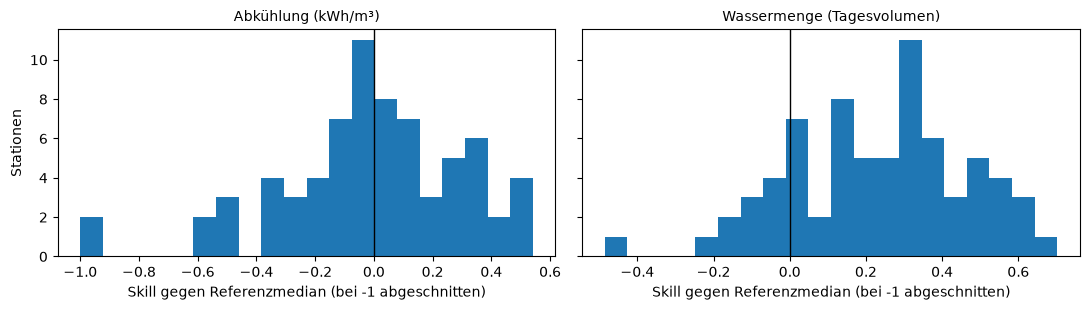

In [4]:
g = tm.guete(r["modelltage"], ref, r["modelle"], termine)
display(g.groupby("kanal")["skill"].describe().round(2))
display(g.groupby("kanal")["skill"].apply(lambda s: (s > 0).mean())
        .rename("Anteil Skill > 0").round(2).to_frame())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, (kanal, titel) in zip(ax, tm.KANAELE.items()):
    s = g.loc[g["kanal"] == kanal, "skill"].clip(-1, 1)
    a.hist(s, bins=20, color="C0")
    a.axvline(0, color="k", lw=1)
    a.set_title(titel, fontsize=10)
    a.set_xlabel("Skill gegen Referenzmedian (bei -1 abgeschnitten)")
ax[0].set_ylabel("Stationen")
plt.tight_layout()
plt.show()

- Für die Wassermenge hilft die Temperatur deutlich, für die Abkühlung in kWh/m³ im Median nicht; dort ist die Kennlinie im Winter fast eine Konstante. Dem CUSUM reicht das als stabile Erwartung.

## Beispiel 68956351

- Die Station mit dem drei Jahre offenen Ventil. Dritte Zeile im Stationsblatt: CUSUM-Konten beider Kanäle, grau das Referenzjahr, rote Linie die Reparatur.
- `richtung` in der Alarmtabelle: bei kWh/m³ heißt 1 mehr Abkühlung (besser), bei der Wassermenge mehr Wasser (schlechter).

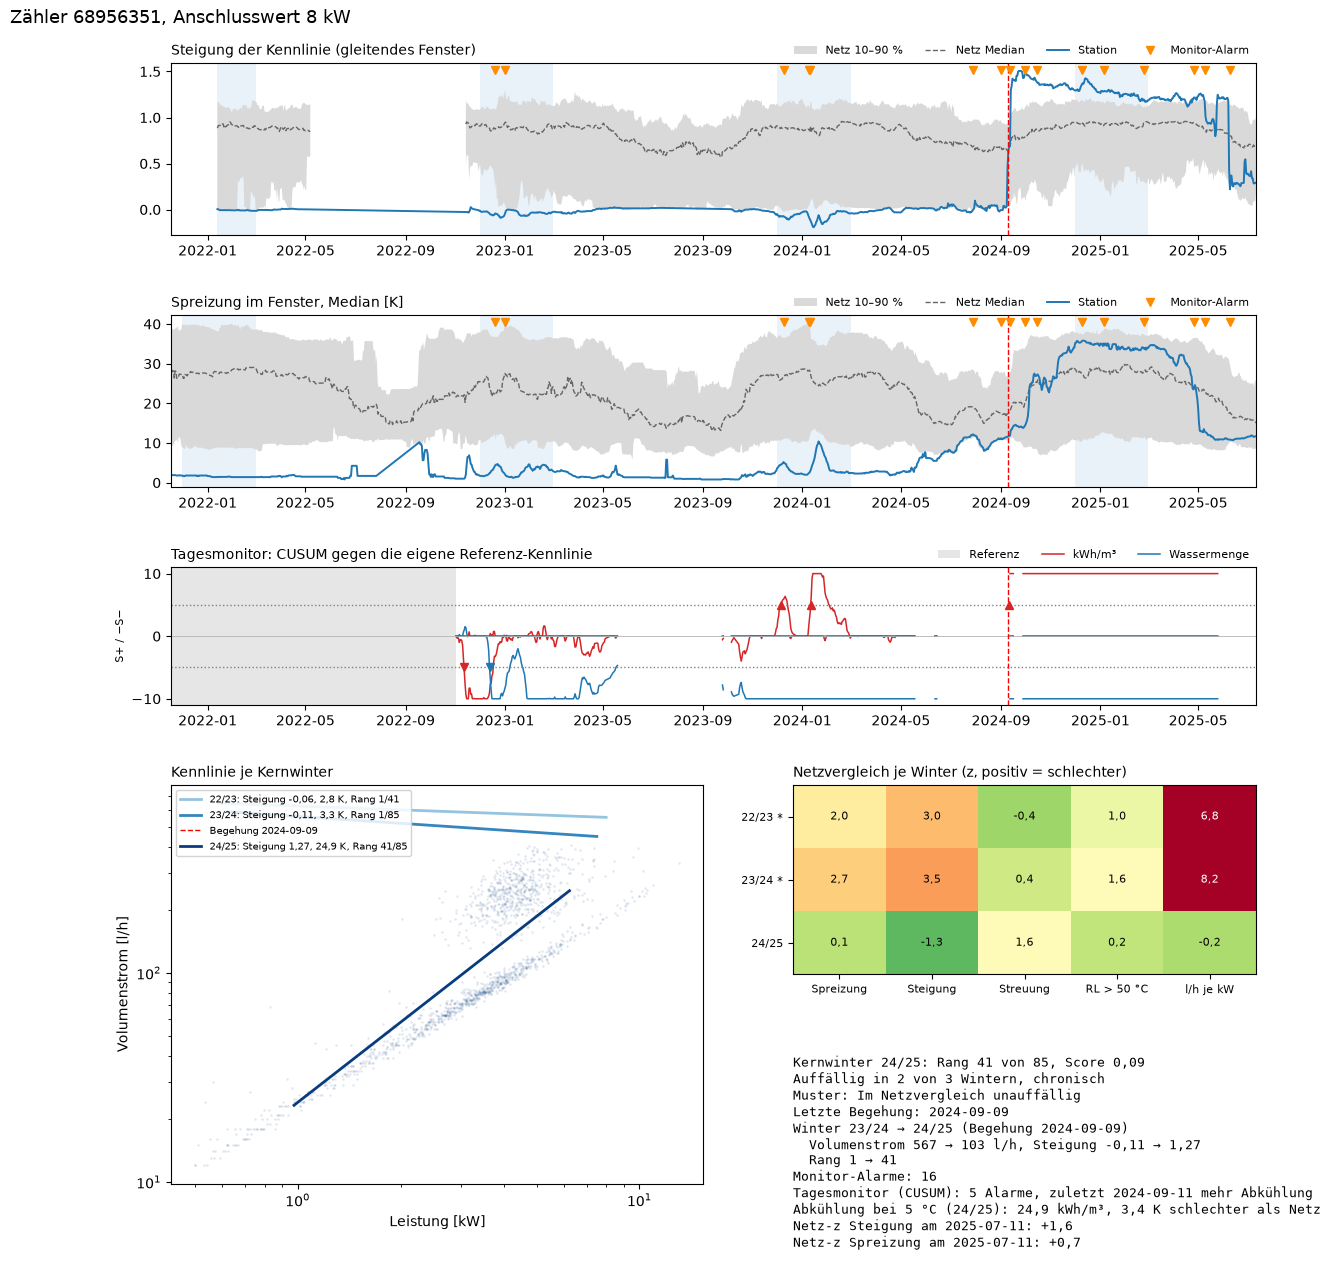

,meter,kanal,datum,richtung,beginn
234,68956351,kwh_pro_m3,2022-11-12,-1,2022-11-03
235,68956351,kwh_pro_m3,2023-12-06,1,2023-11-29
236,68956351,kwh_pro_m3,2024-01-12,1,2024-01-08
237,68956351,kwh_pro_m3,2024-09-11,1,2024-09-11
238,68956351,log_volumen,2022-12-14,-1,2022-12-09


In [5]:
fig = bl.zeichne_stationsblatt(BEISPIEL, erg)
plt.show()
display(r["alarme"][r["alarme"]["meter"] == BEISPIEL])

- Grenze jedes Selbstvergleichs: Das Referenzjahr ist der Zustand mit offenem Ventil, der Monitor lernt den Fehler als normal.
- Der Alarm zwei Tage nach der Reparatur heißt „mehr Abkühlung als früher“, also eine Verbesserung.
- Dass die Station vorher die schlechteste im Netz war, zeigen erst der Netzvergleich (Rang 1 in 22/23 und 23/24) und die Abkühlung bei 5 °C.

## Alarmlast

- Alarme je überwachter Station, normiert auf 100 überwachte Heiztage.

In [6]:
al = r["alarme"]
ok = ref[ref["status"] == "ok"]
je_station = al.groupby("meter").size().reindex(ok.index, fill_value=0)
rate = 100 * je_station / ok["ueberwachte_tage"]
print(f"{len(al)} Alarme bei {al['meter'].nunique()} von {len(ok)} "
      f"überwachten Stationen")
print(f"je 100 überwachte Heiztage: Median {rate.median():.1f}, "
      f"oberes Quartil {rate.quantile(0.75):.1f}")
display(al.groupby(["kanal", "richtung"]).size().rename("Alarme").to_frame())

592 Alarme bei 87 von 92 überwachten Stationen
je 100 überwachte Heiztage: Median 1.2, oberes Quartil 1.7


Alarme
kanal       richtung        
kwh_pro_m3  -1           160
             1            95
log_volumen -1           206
             1           131

## Treffertest gegen Notebook 14

- Fälle: datierte Begehungen; mechanisch heißt, der Freitext nennt Schmutzfänger, Ventil, Pumpe, Zirkulation oder Volumenstrom.
- Treffer: Alarm 7 Tage vor bis 60 Tage nach dem Termin. Kontrollquote: Anteil der Stationen ohne Begehung mit Alarm im selben Fenster.
- Hebel = Trefferquote / Kontrollquote, um 1 heißt nicht besser als Zufall. Die Alarme aus Notebook 14 laufen durch denselben Test.

In [7]:
faelle = tm.faelle(bc.kodiere_begehungen())
beob = tm.beobachtete_tage(r["verlauf"])
print(f"{len(faelle)} datierte Begehungsfälle, davon "
      f"{int(faelle['mechanisch'].sum())} mechanisch")

t_tm = tm.treffertest(faelle, r["alarme"], beob, termine)
a14 = erg["monitor"]["alarme"].rename(columns={"kennzahl": "kanal"})
t_14 = tm.treffertest(faelle, a14, beob, termine, pruefungen={
    "NB 14 Steigung": ["steigung"],
    "NB 14 Residuum": ["residuum_median"],
    "NB 14 einer der beiden": ["steigung", "residuum_median"]})
treffer = pd.concat([t_tm, t_14], ignore_index=True)
display(tm.bilanz(treffer, ["pruefung"]).round(3))
display(tm.bilanz(treffer, ["pruefung", "mechanisch"]).round(3))

58 datierte Begehungsfälle, davon 19 mechanisch


,pruefung,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,43,23,0.535,0.267,2.006,0.000
1,Wassermenge,43,22,0.512,0.408,1.254,0.111
2,einer der beiden,43,30,0.698,0.535,1.303,0.022
3,NB 14 Steigung,43,27,0.628,0.593,1.059,0.380
4,NB 14 Residuum,43,21,0.488,0.431,1.134,0.270
5,NB 14 einer der beiden,43,31,0.721,0.683,1.056,0.361


,pruefung,mechanisch,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,True,14,5,0.357,0.260,1.374,0.288
1,Wassermenge,True,14,9,0.643,0.426,1.509,0.086
2,einer der beiden,True,14,10,0.714,0.542,1.318,0.153
3,Abkühlung,False,29,18,0.621,0.270,2.300,0.000
4,Wassermenge,False,29,13,0.448,0.399,1.123,0.360
5,einer der beiden,False,29,20,0.690,0.532,1.297,0.063
6,NB 14 Steigung,True,14,10,0.714,0.626,1.142,0.350
7,NB 14 Residuum,True,14,9,0.643,0.469,1.371,0.150
8,NB 14 einer der beiden,True,14,11,0.786,0.717,1.095,0.411
9,NB 14 Steigung,False,29,17,0.586,0.577,1.016,0.537


- Nur der Abkühlungskanal hat einen klaren Hebel: 23 von 43 Begehungen mit Alarm gegen 27 % bei den Kontrollen, Hebel 2,0, p < 0,001.
- Der Fenstermonitor aus Notebook 14 kommt nur auf etwa 1,1, weil er auch ohne Begehung sehr oft anschlägt.
- Ein Alarm nach einer Begehung passt zu einer Veränderung, beweist sie nicht: Begangen wurde vor allem im Herbst.

## Wirkung: wetterbereinigte Differenz-in-Differenzen

- Je Begehung und Kanal: Median der Residuen der ersten 30 Heiztage nach dem Termin minus der letzten 30 davor, abzüglich derselben Differenz bei Stationen ohne Begehung.
- Bei einer Verbesserung erwartet: mehr Abkühlung, weniger Wasser (in Prozent).

In [8]:
w = tm.wirkung(r["verlauf"], faelle, termine)
display(tm.wirkung_bilanz(w).round(3))
display(tm.wirkung_bilanz(w, ["kanal", "mechanisch"]).round(3))

,kanal,Faelle,Median Δ begangen,Median Δ Kontrolle,Median DiD,Anteil in erwarteter Richtung,p (Wilcoxon),Einheit
0,kwh_pro_m3,24,2.309,-0.354,2.228,0.625,0.042,kWh/m³
1,log_volumen,24,-0.160,9.164,-7.581,0.708,0.053,%


,kanal,mechanisch,Faelle,Median Δ begangen,Median Δ Kontrolle,Median DiD,Anteil in erwarteter Richtung,p (Wilcoxon),Einheit
0,kwh_pro_m3,True,7,3.772,-0.747,4.519,0.857,0.047,kWh/m³
1,log_volumen,True,7,-0.843,9.164,-10.468,0.857,0.031,%
2,kwh_pro_m3,False,17,1.029,0.084,1.029,0.529,0.353,kWh/m³
3,log_volumen,False,17,1.003,5.247,-7.216,0.647,0.431,%


- Abgleich mit dem Wintervergleich aus Notebook 20: DiD gegen Änderung der Kennliniensteigung und Verhältnis der Volumenströme.

In [9]:
wv = erg["vergleich"]
wv = wv[wv["status"] == "ok"][["meter", "datum", "d_steigung",
                               "flow_verhaeltnis"]].copy()
wv["datum"] = pd.to_datetime(wv["datum"]).dt.normalize()
zeilen = []
for kanal in tm.KANAELE:
    m = w[w["kanal"] == kanal].merge(wv, on=["meter", "datum"])
    for spalte in ("d_steigung", "flow_verhaeltnis"):
        rho, p = stats.spearmanr(m["did"], m[spalte])
        zeilen.append({"kanal": kanal, "Wintervergleich": spalte,
                       "Begehungen": len(m), "Spearman": rho, "p": p})
pd.DataFrame(zeilen).round(3)

,kanal,Wintervergleich,Begehungen,Spearman,p
0,kwh_pro_m3,d_steigung,23,0.459,0.028
1,kwh_pro_m3,flow_verhaeltnis,23,-0.394,0.063
2,log_volumen,d_steigung,23,-0.622,0.002
3,log_volumen,flow_verhaeltnis,23,0.383,0.071


- Beide Wirkungsmaße zeigen in dieselbe Richtung: mehr Abkühlung und weniger Wasser gehen mit steilerer Kennlinie einher.
- Nicht unabhängig (dieselben Zähler), aber verschiedene Zeiträume (30 Heiztage gegen Kernwinter) und Größen. Die DiD hat die bessere Kontrolle, der Wintervergleich gleiche Jahreszeiten; beide bleiben.

## Gegenprobe: Abkühlung bei 5 °C gegen das Netz

- Je Station und Kernwinter eine Theil-Sen-Gerade kWh/m³ über der Tagesmitteltemperatur, ausgewertet bei 5 °C.
- Abstand zum Netzmedian in Kelvin Spreizung (kWh/m³ / 1,15), positiv heißt schlechter, BHKW nicht im Median.
- Findet diese einfache Größe dieselben Stationen wie der Netzscore aus Notebook 20?

,Stationen,mit_Netzwert,Netzmedian
winter,,,
21/22,48,46,27.6
22/23,47,46,24.6
23/24,91,90,28.3
24/25,90,88,28.9
25/26,4,0,NaN


,winter,Stationen,Spearman,p,auffällig unter den 10 schlechtesten bei 5 °C
0,22/23,41,0.870,0.0,0.5
1,23/24,85,0.873,0.0,0.8
2,24/25,85,0.889,0.0,0.8


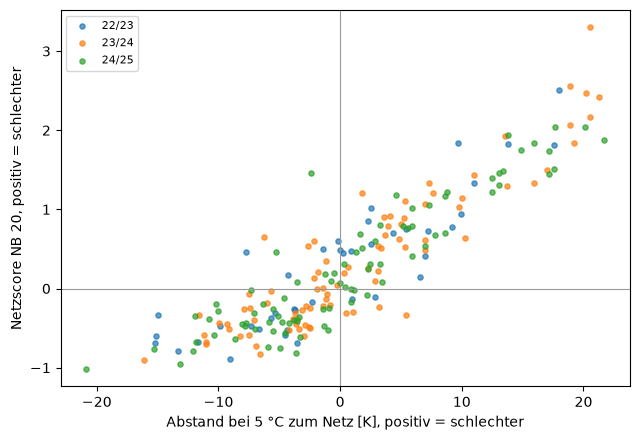

In [10]:
norm = r["norm"]
display(norm.groupby("winter").agg(Stationen=("meter", "size"),
                                   mit_Netzwert=("abstand_k", "count"),
                                   Netzmedian=("netz_median", "first"))
        .round(1))
mk = erg["markiert"][["meter", "winter", "score", "rang", "auffaellig"]]
x = norm.merge(mk, on=["meter", "winter"], suffixes=("_5c", "_netz"))
x = x.dropna(subset=["abstand_k", "score"])
zeilen = []
for winter, d in x.groupby("winter"):
    rho, p = stats.spearmanr(d["abstand_k"], d["score"])
    oben = d.nsmallest(10, "rang_5c")["auffaellig"].mean()
    zeilen.append({"winter": winter, "Stationen": len(d), "Spearman": rho,
                   "p": p, "auffällig unter den 10 schlechtesten bei 5 °C": oben})
display(pd.DataFrame(zeilen).round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for winter, d in x.groupby("winter"):
    ax.scatter(d["abstand_k"], d["score"], s=14, label=winter, alpha=0.7)
ax.axhline(0, color="0.6", lw=0.8)
ax.axvline(0, color="0.6", lw=0.8)
ax.set_xlabel("Abstand bei 5 °C zum Netz [K], positiv = schlechter")
ax.set_ylabel("Netzscore NB 20, positiv = schlechter")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
for m in (80956410, 68956372, BEISPIEL):
    n = norm[norm["meter"] == m][["winter", "norm_kwh_m3", "abstand_k", "rang",
                                  "n_stationen"]]
    s = mk[mk["meter"] == m][["winter", "score", "rang", "auffaellig"]]
    print(f"Zähler {m}")
    display(n.merge(s, on="winter", how="outer", suffixes=("_5c", "_netz"))
            .round(2))

Zähler 80956410


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,23/24,27.72,0.50,44.0,90,-0.31,62.0,False
1,24/25,9.18,17.14,6.0,87,1.74,7.0,True


Zähler 68956372


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,21/22,29.81,-1.95,28.0,46,NaN,NaN,NaN
1,22/23,28.64,-3.53,28.0,46,-0.69,38.0,False
2,23/24,3.84,21.27,1.0,90,2.42,4.0,True
3,24/25,22.08,5.93,24.0,87,0.41,33.0,False
4,25/26,17.92,NaN,NaN,4,NaN,NaN,False


Zähler 68956351


,winter,norm_kwh_m3,abstand_k,rang_5c,n_stationen,score,rang_netz,auffaellig
0,21/22,4.54,20.02,2.0,46,NaN,NaN,NaN
1,22/23,3.93,17.95,1.0,46,2.51,1.0,True
2,23/24,4.65,20.57,2.0,90,3.30,1.0,True
3,24/25,24.94,3.44,29.0,87,0.09,41.0,False


- Ja, aber zum Teil eingebaut: kWh/m³ ist bis auf einen Faktor die Spreizung, und die steckt auch im Netzscore. Unabhängig sind Datenbasis und Methode; das spricht dafür, dass der Netzvergleich kein Artefakt seiner Kennzahlauswahl ist.
- Einzelfälle passen: 68956372 steht in 23/24 bei 5 °C auf Rang 1 und im Netzscore auf Rang 4, danach unauffällig; 68956351 ist vor der Reparatur bei beiden unter den schlechtesten zwei, danach im Mittelfeld.

## Zusammenfassung & Bewertung

- Ins finale Modell übernommen: der Tagesmonitor als einziger Alarmkanal im Stationsblatt (statt des Fensteralarms aus Notebook 14), die Abkühlung bei 5 °C als Gegenprobe in der Statustabelle (nicht im Score) und die DiD neben dem Wintervergleich.
- Belastbar ist der Treffertest des Abkühlungskanals (Hebel 2,0 gegen etwa 1,1 beim Fenstermonitor) und die fast gleiche Ordnung von Abkühlung bei 5 °C und Netzscore (Spearman um 0,88 in allen drei Wintern).
- Schwach bleibt einiges. Für kWh/m³ hilft die Temperatur kaum (Skill im Median 0). Die Wirkungsmessung hat nur 24 Fälle je Kanal (p = 0,04 und 0,05), die mechanischen Fälle (7) zeigen den deutlichsten Effekt.
- Die Alarmlast ist hoch, fast jede überwachte Station hat Alarme; ein Alarm allein ist kein Grund für eine Begehung. Einen als normal gelernten Fehler sieht der Monitor nicht, dafür steht der Netzvergleich daneben.
- Offen: die Alarmschwelle h (weniger Alarme gegen spätere Meldung).